# 03 · Model comparison, uncertainty and explainability

Run `python -m hospital_readmission.run` first to execute the actual CPU experiment. This notebook reads its measured outputs and locally fitted model; it does not fabricate metrics or rerun tuning when opened. Model selection uses **mean training CV average precision**, followed by a validation-only maximum-F2 threshold. Test metrics are reported after those choices are frozen.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hospital_readmission").is_dir())
def report(name):
    return json.loads((ROOT / "reports" / name).read_text())
def figure(name):
    display(Image(filename=str(ROOT / "figures" / name)))
from hospital_readmission.data import load_diabetes
from hospital_readmission.cohort import make_cohort
from hospital_readmission.config import ExperimentConfig
from hospital_readmission.splitting import split_patients
dataset = load_diabetes()
cohort, cohort_audit = make_cohort(dataset)
splits, split_audit = split_patients(cohort, ExperimentConfig())
training = cohort.iloc[splits["train"]]
print("Real ZIP loaded offline:", dataset.data.shape, "eligible:", cohort.shape)


Real ZIP loaded offline: (101766, 50) eligible: (99319, 50)


In [2]:
selection = report("selection.json")
comparison = pd.read_csv(ROOT / "reports/model_comparison.csv")
display(comparison.sort_values("cv_average_precision", ascending=False))
print("Selected before test evaluation:", selection["model"])
print("Thresholds:", selection["thresholds"])
assert selection["test_used_for_selection"] is False

,model,selected_by_training_cv,cv_average_precision,n,positives,prevalence,roc_auc,average_precision,precision,recall,specificity,f1,brier_score,expected_calibration_error,threshold
3,XGBoost,True,0.220596,19861,2260,0.113791,0.669344,0.225931,0.158234,0.727876,0.502812,0.259956,0.096040,0.002411,0.093570
2,Random Forest,False,0.214321,19861,2260,0.113791,0.660166,0.211355,0.152070,0.749115,0.463667,0.252819,0.097241,0.010418,0.099574
1,Logistic Regression,False,0.210609,19861,2260,0.113791,0.660330,0.213563,0.148706,0.742478,0.454236,0.247785,0.096842,0.002197,0.088910
0,Dummy,False,0.113803,19861,2260,0.113791,0.500000,0.113791,0.113791,1.000000,0.000000,0.204331,0.100842,0.000012,0.113803


Selected before test evaluation: XGBoost
Thresholds: {'Dummy': 0.11380297643394267, 'Logistic Regression': 0.08891049387680909, 'Random Forest': 0.09957395959828823, 'XGBoost': 0.0935702919960022}


In [3]:
for path in sorted((ROOT / "reports").glob("cv_*.csv")):
    print(path.stem)
    search = pd.read_csv(path)
    display(search[["params","mean_test_ap","std_test_ap","mean_test_roc_auc"]])

cv_logistic_regression


,params,mean_test_ap,std_test_ap,mean_test_roc_auc
0,"{'model__class_weight': None, 'model__C': 0.1}",0.210481,0.005548,0.660367
1,"{'model__class_weight': 'balanced', 'model__C'...",0.210357,0.005002,0.661292
2,"{'model__class_weight': None, 'model__C': 1.0}",0.210609,0.005441,0.659247
3,"{'model__class_weight': 'balanced', 'model__C'...",0.210389,0.005127,0.660454


cv_random_forest


,params,mean_test_ap,std_test_ap,mean_test_roc_auc
0,"{'model__max_depth': 12, 'model__class_weight'...",0.214321,0.004602,0.667285
1,"{'model__max_depth': 18, 'model__class_weight'...",0.214207,0.006002,0.667560
2,"{'model__max_depth': 12, 'model__class_weight'...",0.206012,0.006442,0.665674
3,"{'model__max_depth': 18, 'model__class_weight'...",0.208419,0.006008,0.666339


cv_xgboost


,params,mean_test_ap,std_test_ap,mean_test_roc_auc
0,"{'model__scale_pos_weight': 1.0, 'model__max_d...",0.218807,0.005374,0.668179
1,{'model__scale_pos_weight': 7.7871163948023225...,0.218917,0.004658,0.668820
2,"{'model__scale_pos_weight': 1.0, 'model__max_d...",0.220596,0.004499,0.668572
3,{'model__scale_pos_weight': 7.7871163948023225...,0.219607,0.005180,0.666996


## Untouched test performance
Average precision is the step-weighted area under the precision–recall relationship, not trapezoidal PR area. ROC-AUC describes discrimination; precision/recall/specificity describe the frozen operating point. Brier score and reliability plots assess probability quality. Weighting can improve ranking while distorting absolute probabilities. No calibration was fitted on the test set.

,lower,upper,resamples
roc_auc,0.658275,0.682015,200.0
average_precision,0.211011,0.245448,200.0
brier_score,0.092995,0.099291,200.0


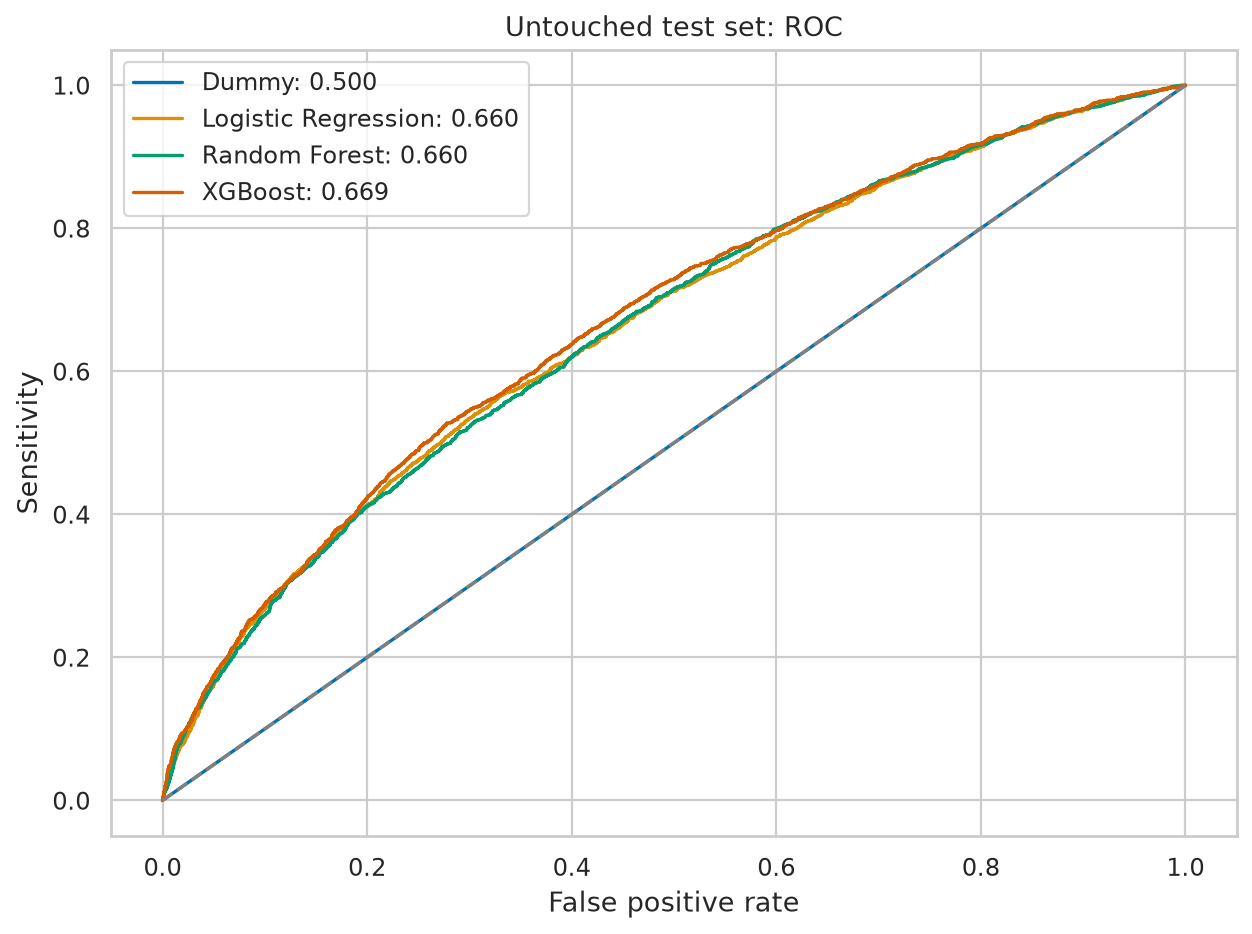

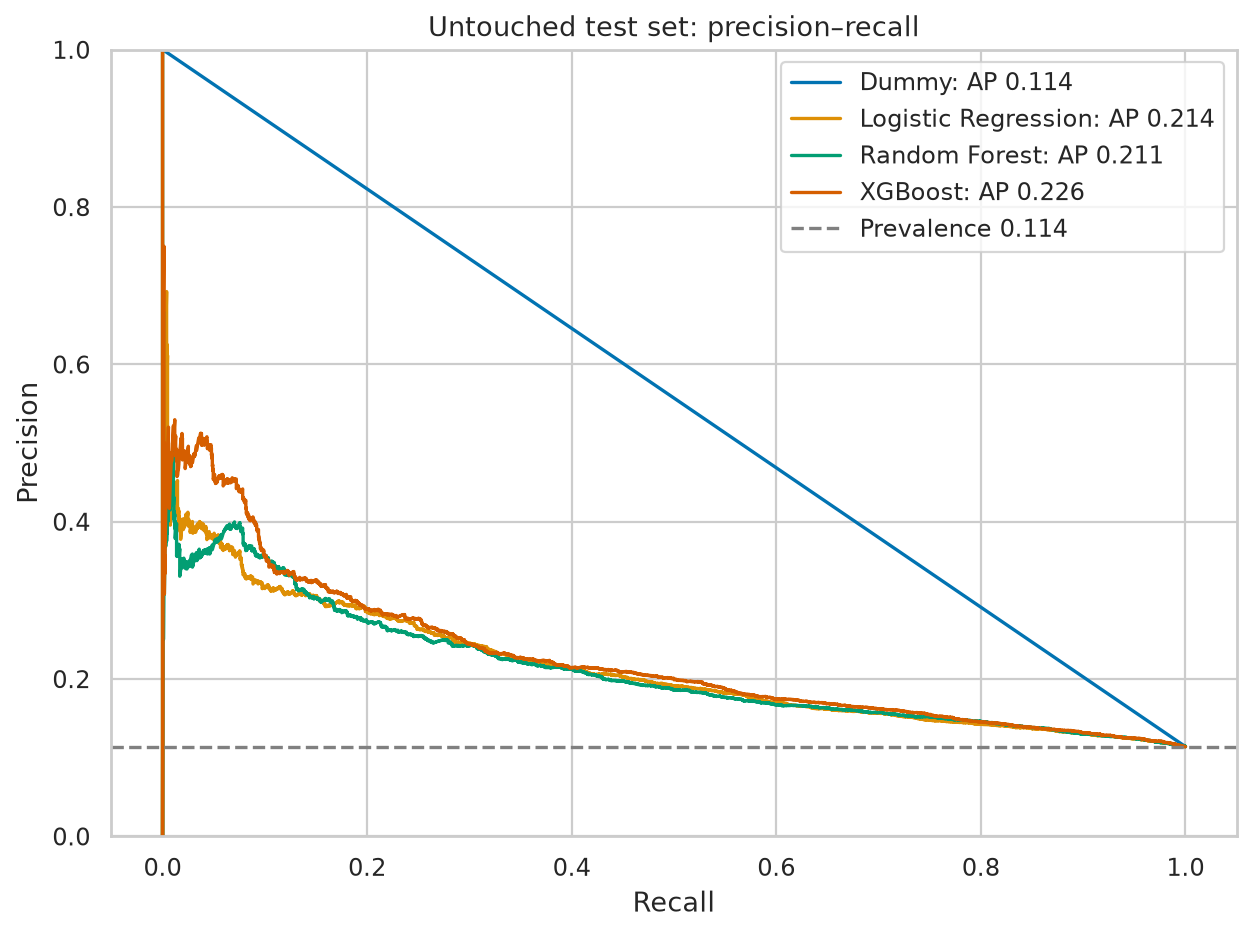

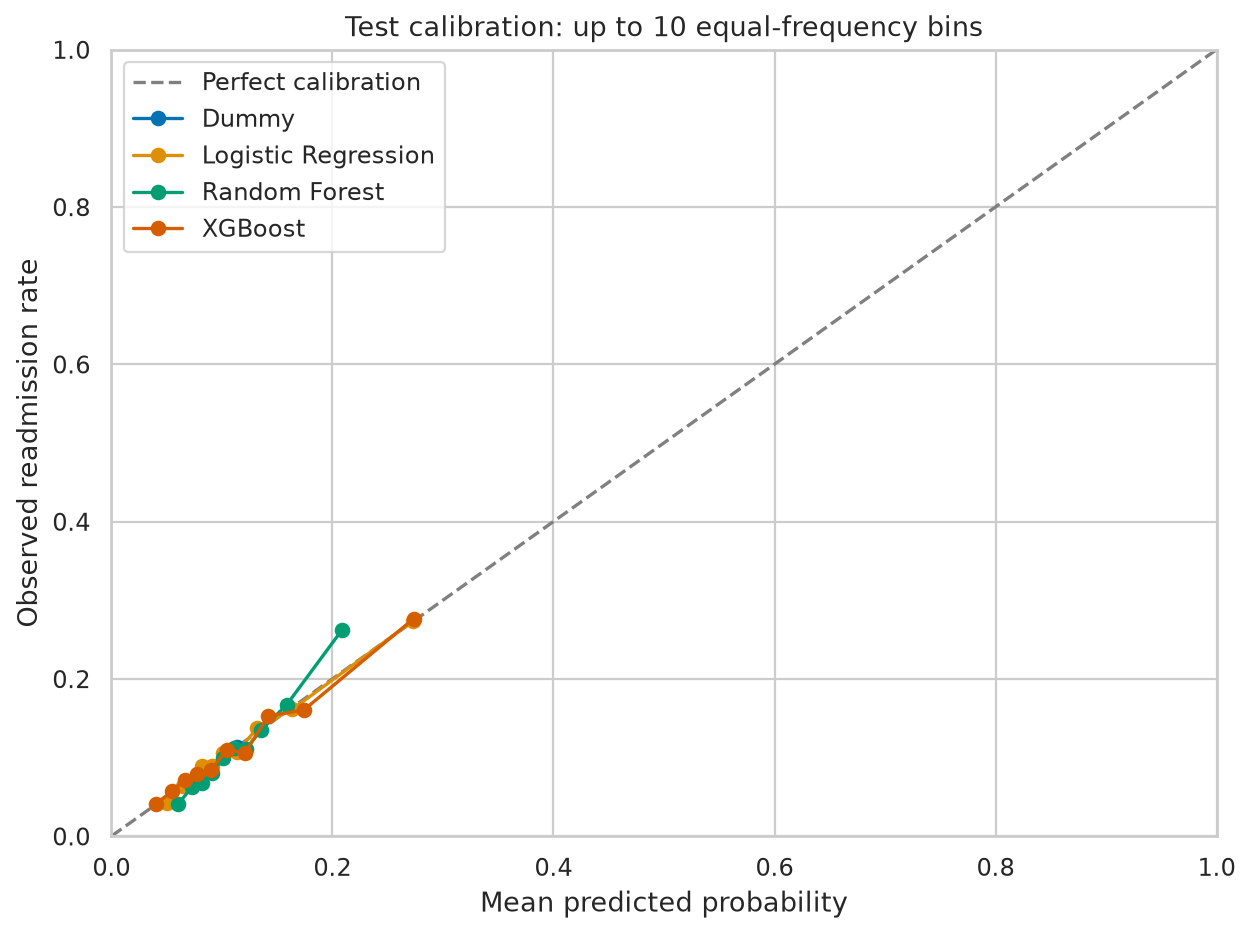

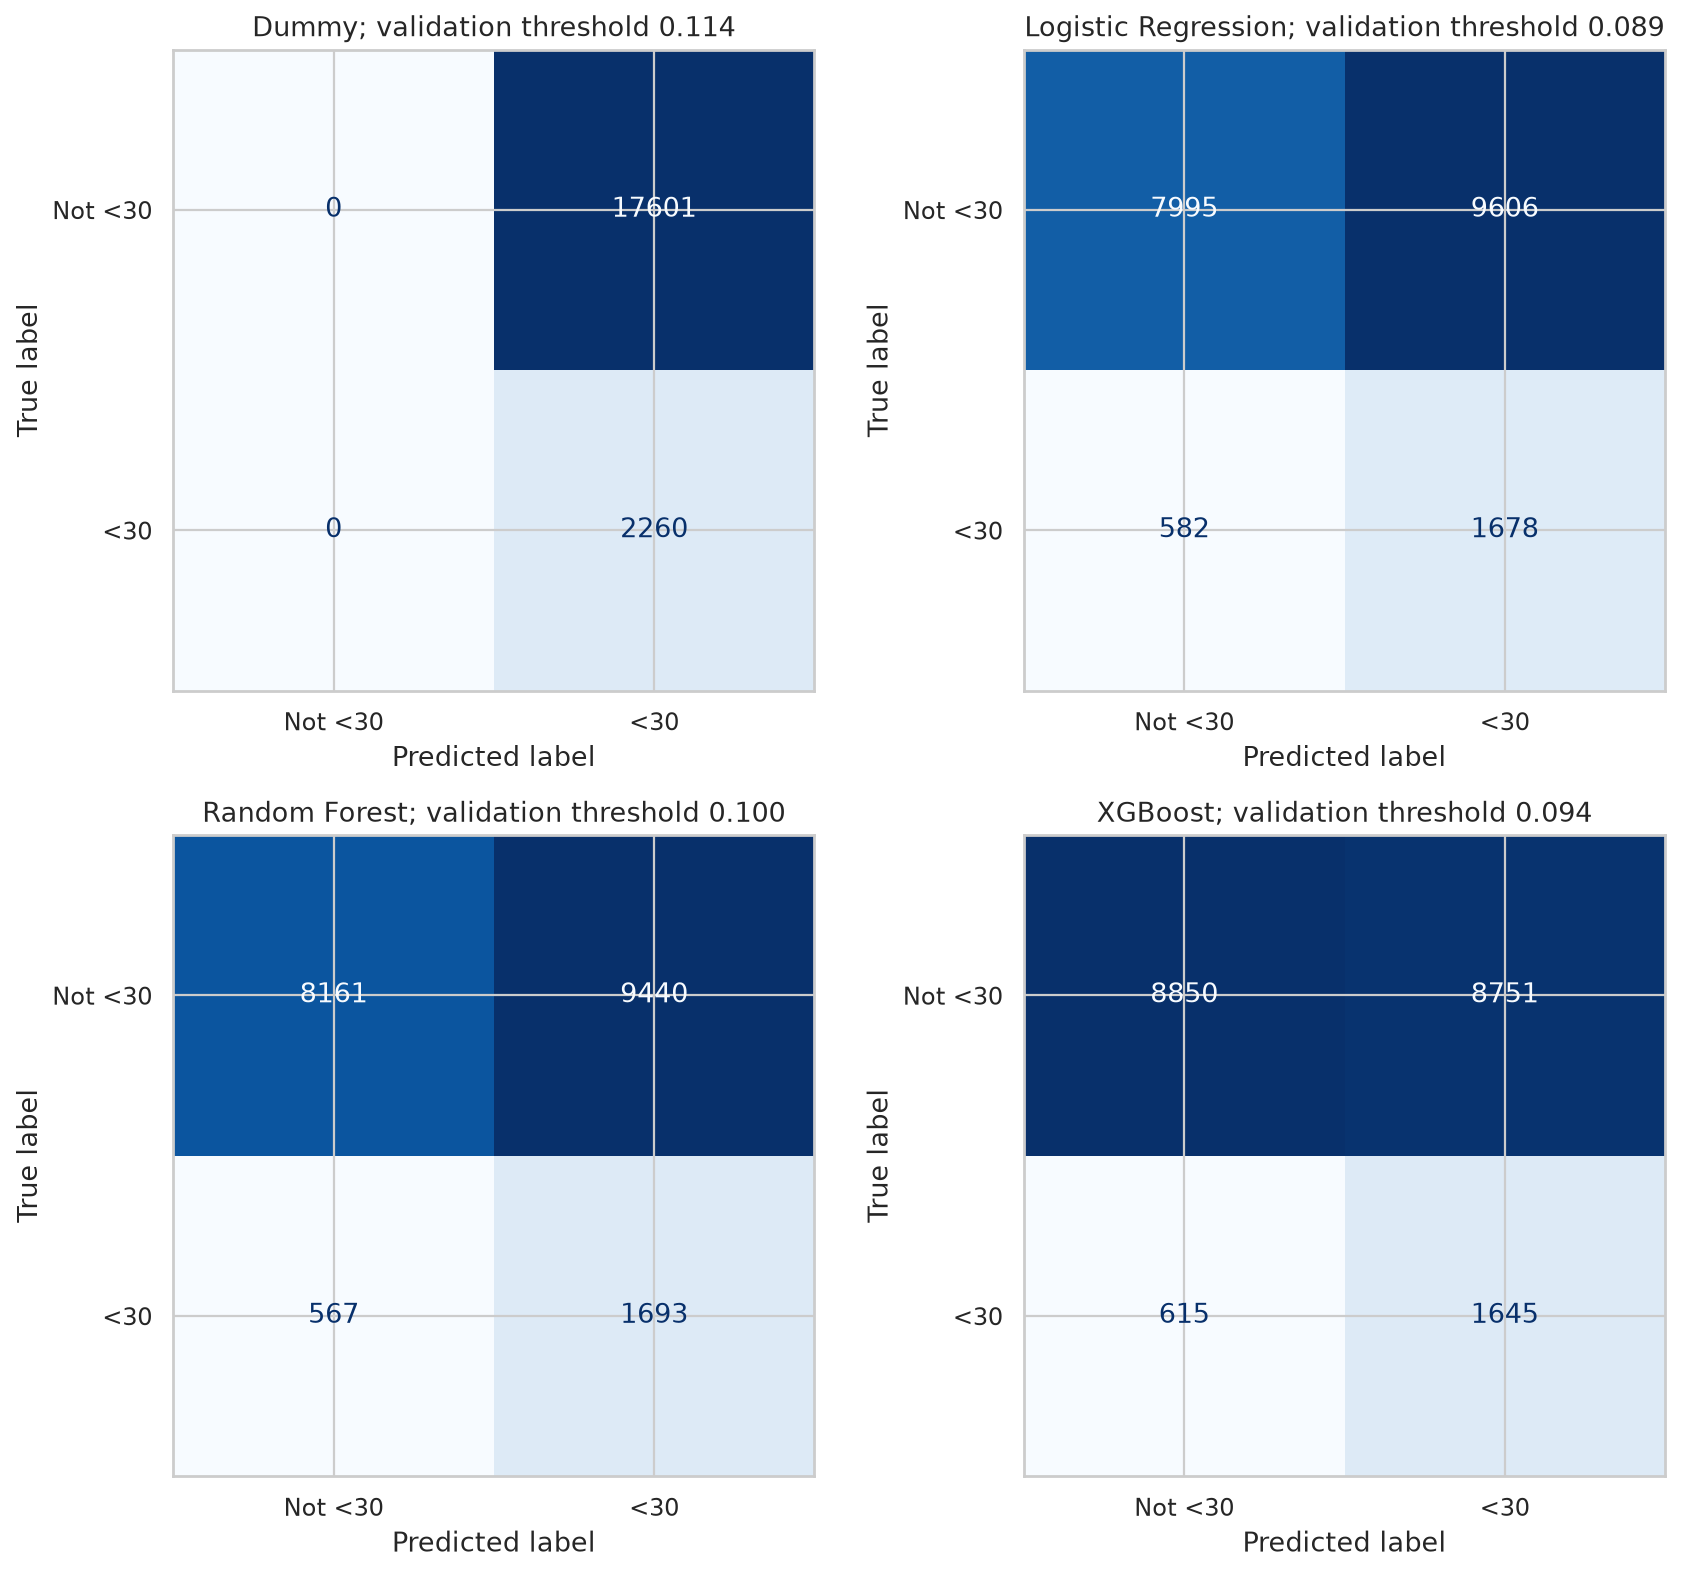

In [4]:
display(pd.DataFrame(report("selected_model_confidence_intervals.json")).T)
figure("test_roc.png")
figure("test_precision_recall.png")
figure("test_calibration.png")
figure("test_confusion_matrices.png")

## Subgroup and error analysis
These are exploratory audits after model selection. Discrimination metrics are withheld for subgroups with fewer than 100 encounters or 20 examples of either outcome. Repeated encounters, uncertain labels and small strata limit fairness conclusions. The confidence intervals above bootstrap patients, not individual rows.

,attribute,group,n,positives,prevalence,sensitivity,specificity,precision,brier_score,roc_auc,average_precision,small_sample_warning
0,age,[0-10),20,0,0.000000,NaN,1.000000,NaN,0.001408,NaN,NaN,True
1,age,[10-20),112,5,0.044643,0.800000,0.859813,0.210526,0.038029,NaN,NaN,True
2,age,[20-30),371,54,0.145553,0.740741,0.618297,0.248447,0.111357,0.743603,0.365400,False
3,age,[30-40),749,82,0.109479,0.658537,0.656672,0.190813,0.087548,0.725838,0.306042,False
4,age,[40-50),1761,165,0.093697,0.666667,0.639098,0.160350,0.078367,0.704293,0.268089,False
5,age,[50-60),3388,330,0.097403,0.621212,0.623283,0.151069,0.084056,0.677448,0.204231,False
6,age,[60-70),4379,489,0.111669,0.695297,0.515681,0.152878,0.096277,0.647075,0.192209,False
7,age,[70-80),5233,641,0.122492,0.776911,0.437936,0.161741,0.102448,0.659415,0.240410,False
8,age,[80-90),3338,428,0.128220,0.820093,0.345361,0.155585,0.107660,0.642426,0.229437,False
9,age,[90-100),510,66,0.129412,0.651515,0.351351,0.129909,0.110592,0.577805,0.211065,False


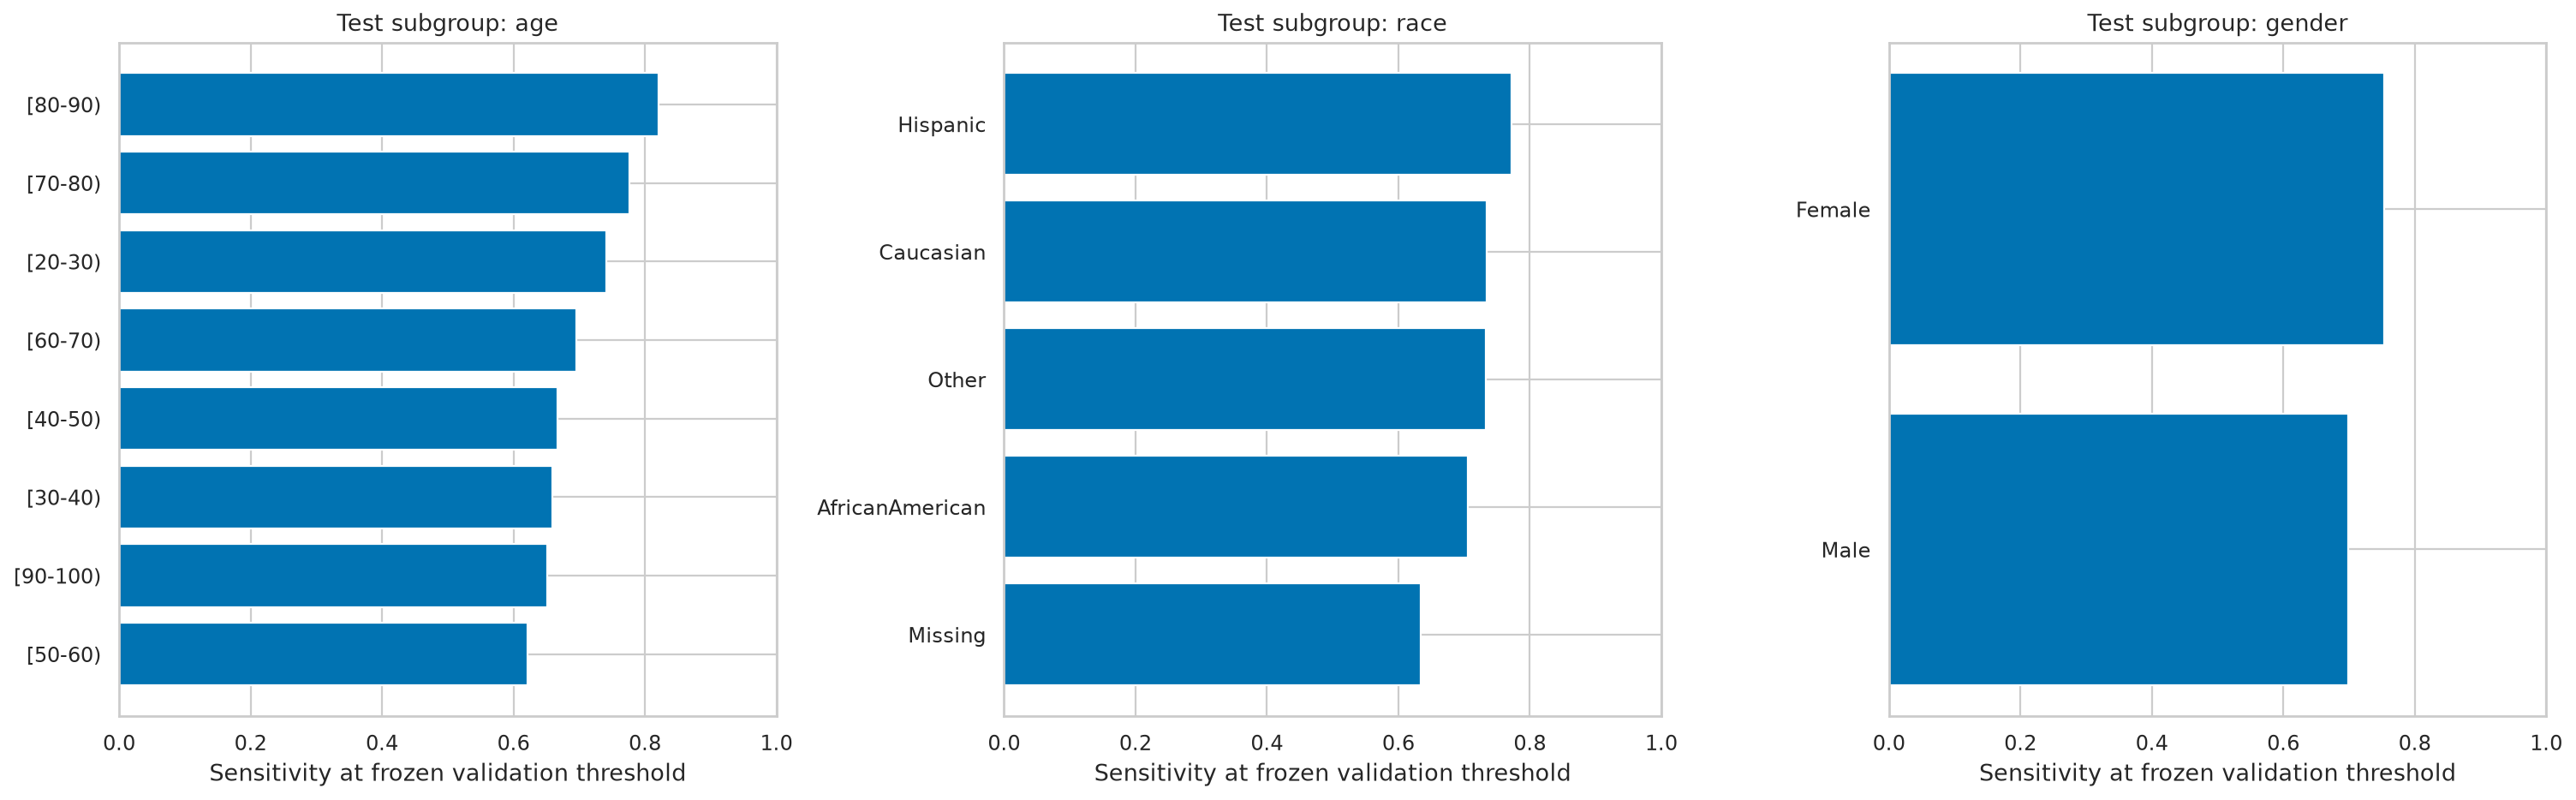

,error_group,time_in_hospital_mean,time_in_hospital_median,number_inpatient_mean,number_inpatient_median,number_emergency_mean,number_emergency_median,number_outpatient_mean,number_outpatient_median,num_medications_mean,num_medications_median,n
0,False negative,3.473171,3.0,0.071545,0.0,0.066667,0.0,0.284553,0.0,14.586992,13.0,615
1,False positive,5.228202,5.0,1.070163,1.0,0.306479,0.0,0.488973,0.0,17.434465,16.0,8751
2,True negative,3.439322,3.0,0.067232,0.0,0.055480,0.0,0.225876,0.0,14.186102,13.0,8850
3,True positive,5.133739,4.0,1.611550,1.0,0.450456,0.0,0.466869,0.0,17.708207,17.0,1645


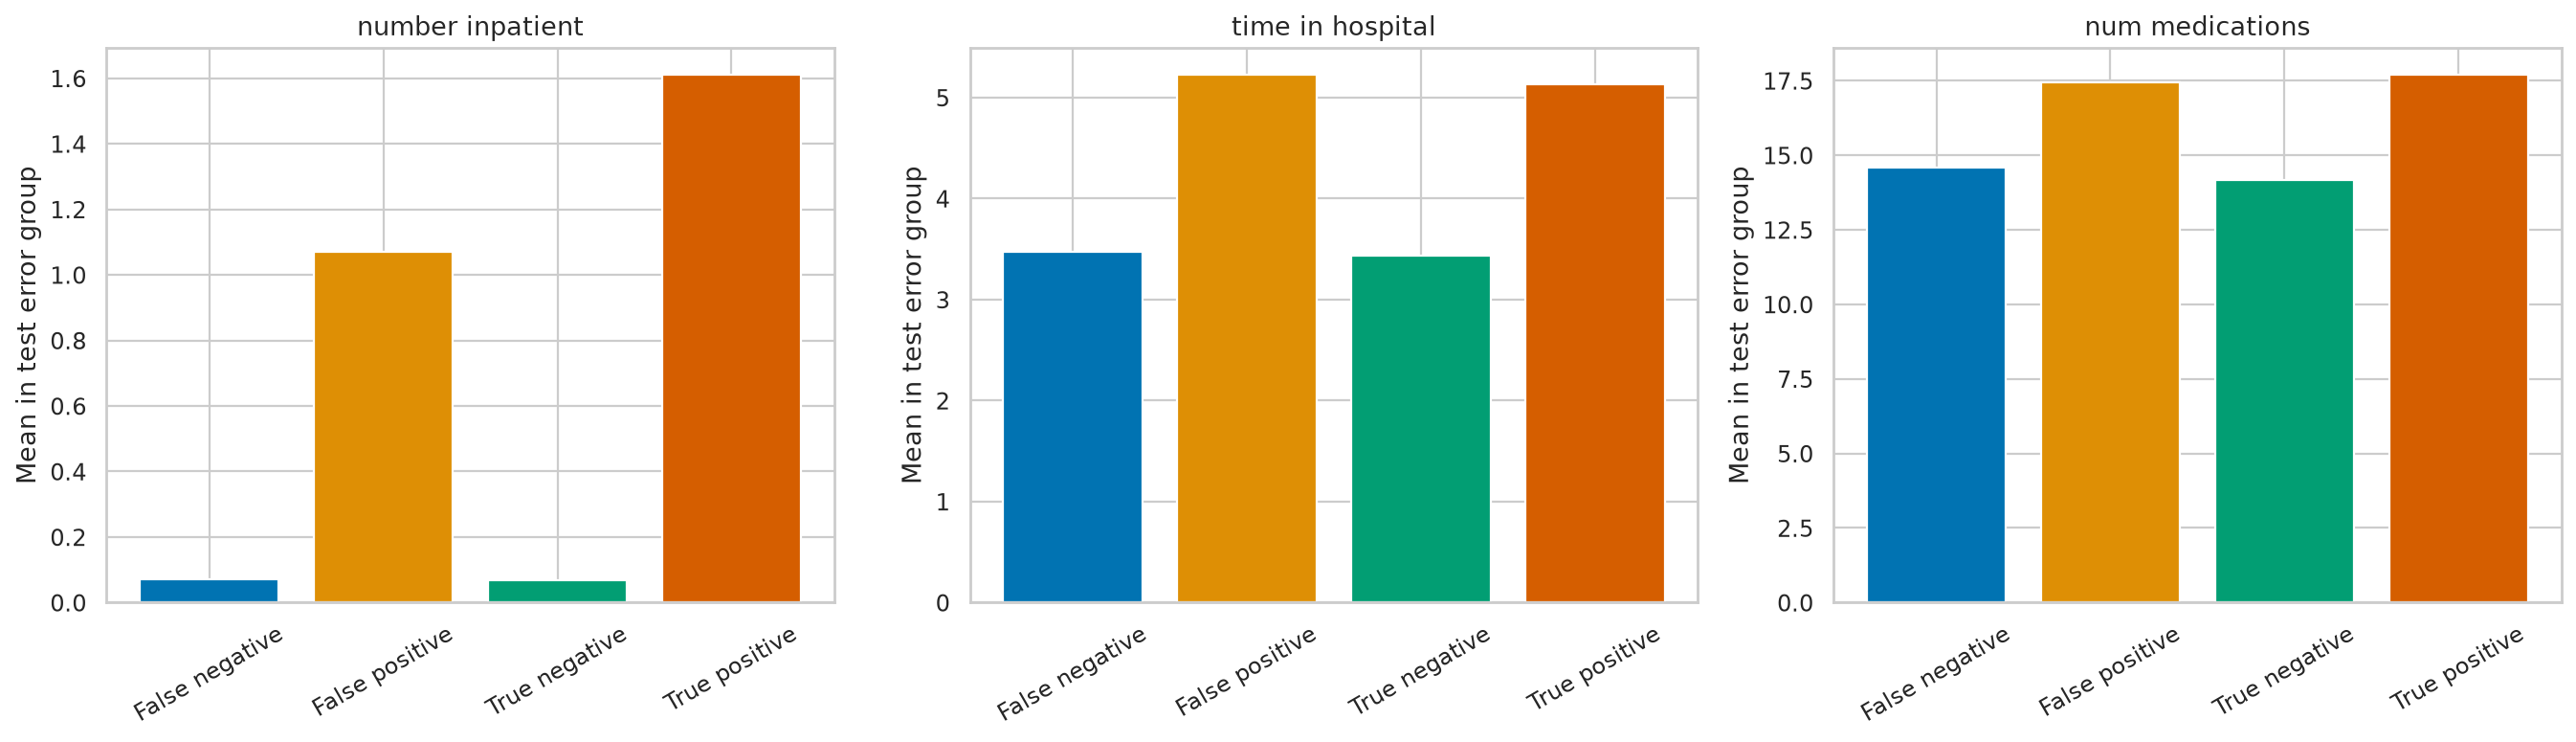

In [5]:
groups = pd.read_csv(ROOT / "reports/test_subgroup_metrics.csv")
display(groups.loc[groups.attribute.isin(["age","race","gender"])])
figure("test_subgroup_sensitivity.png")
display(pd.read_csv(ROOT / "reports/error_analysis.csv"))
figure("test_error_analysis.png")

## SHAP: predictive associations
A fixed random sample of real test encounters is explained after selection. Additivity is verified against the model output. For tree/logistic margins, values are in log odds; for Random Forest they are positive-class probability contributions. Encoded-category features are not independently manipulable causes. No treatment benefit can be inferred from medication SHAP values.

model                                                                      XGBoost
sample_size                                                                     80
feature_count                                                                  185
output_scale                                                              log odds
additivity_verified                                                           True
pipeline_predictions_verified                                                 True
input_representation             original sparse model input; dense data used o...
top_features                     [{'feature': 'numeric__number_inpatient', 'mea...
interpretation                   Predictive associations, not treatment effects...
dtype: object

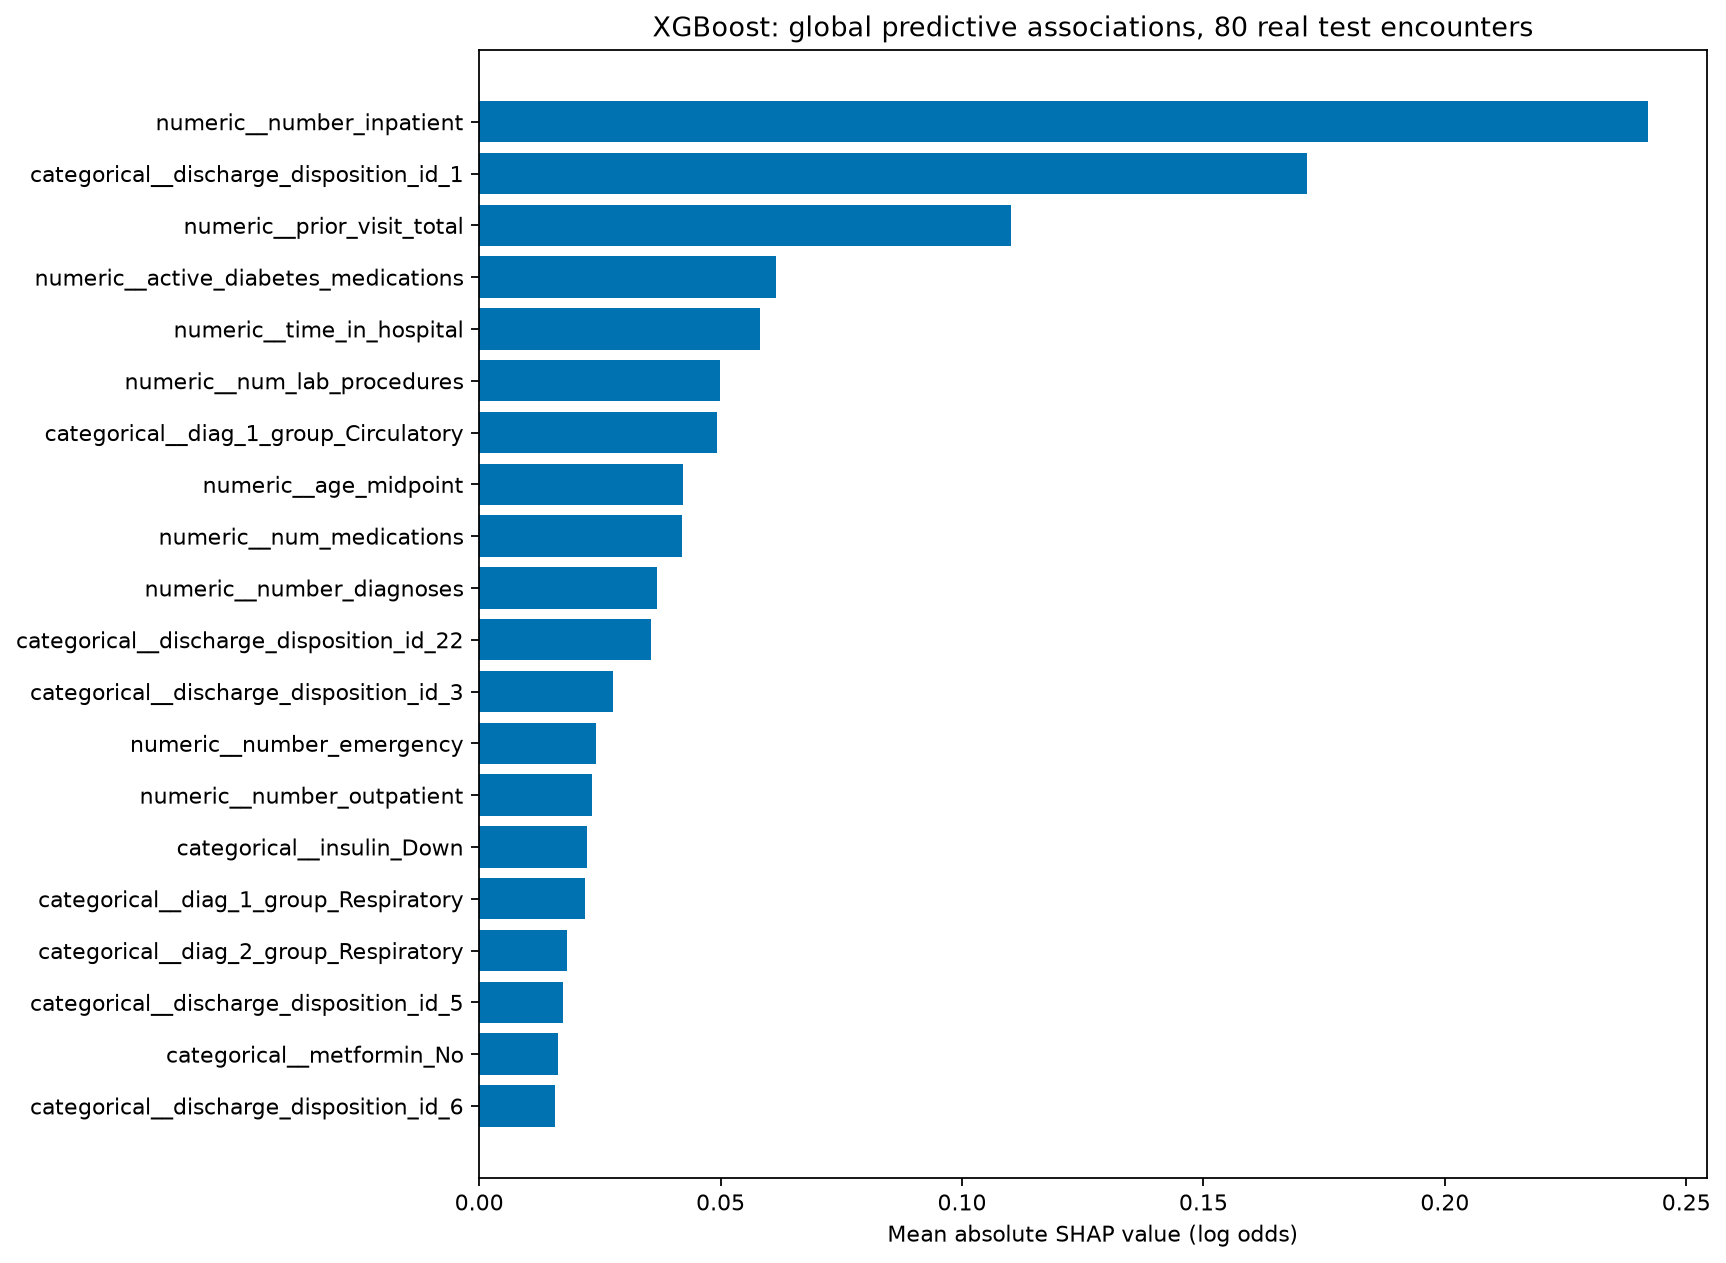

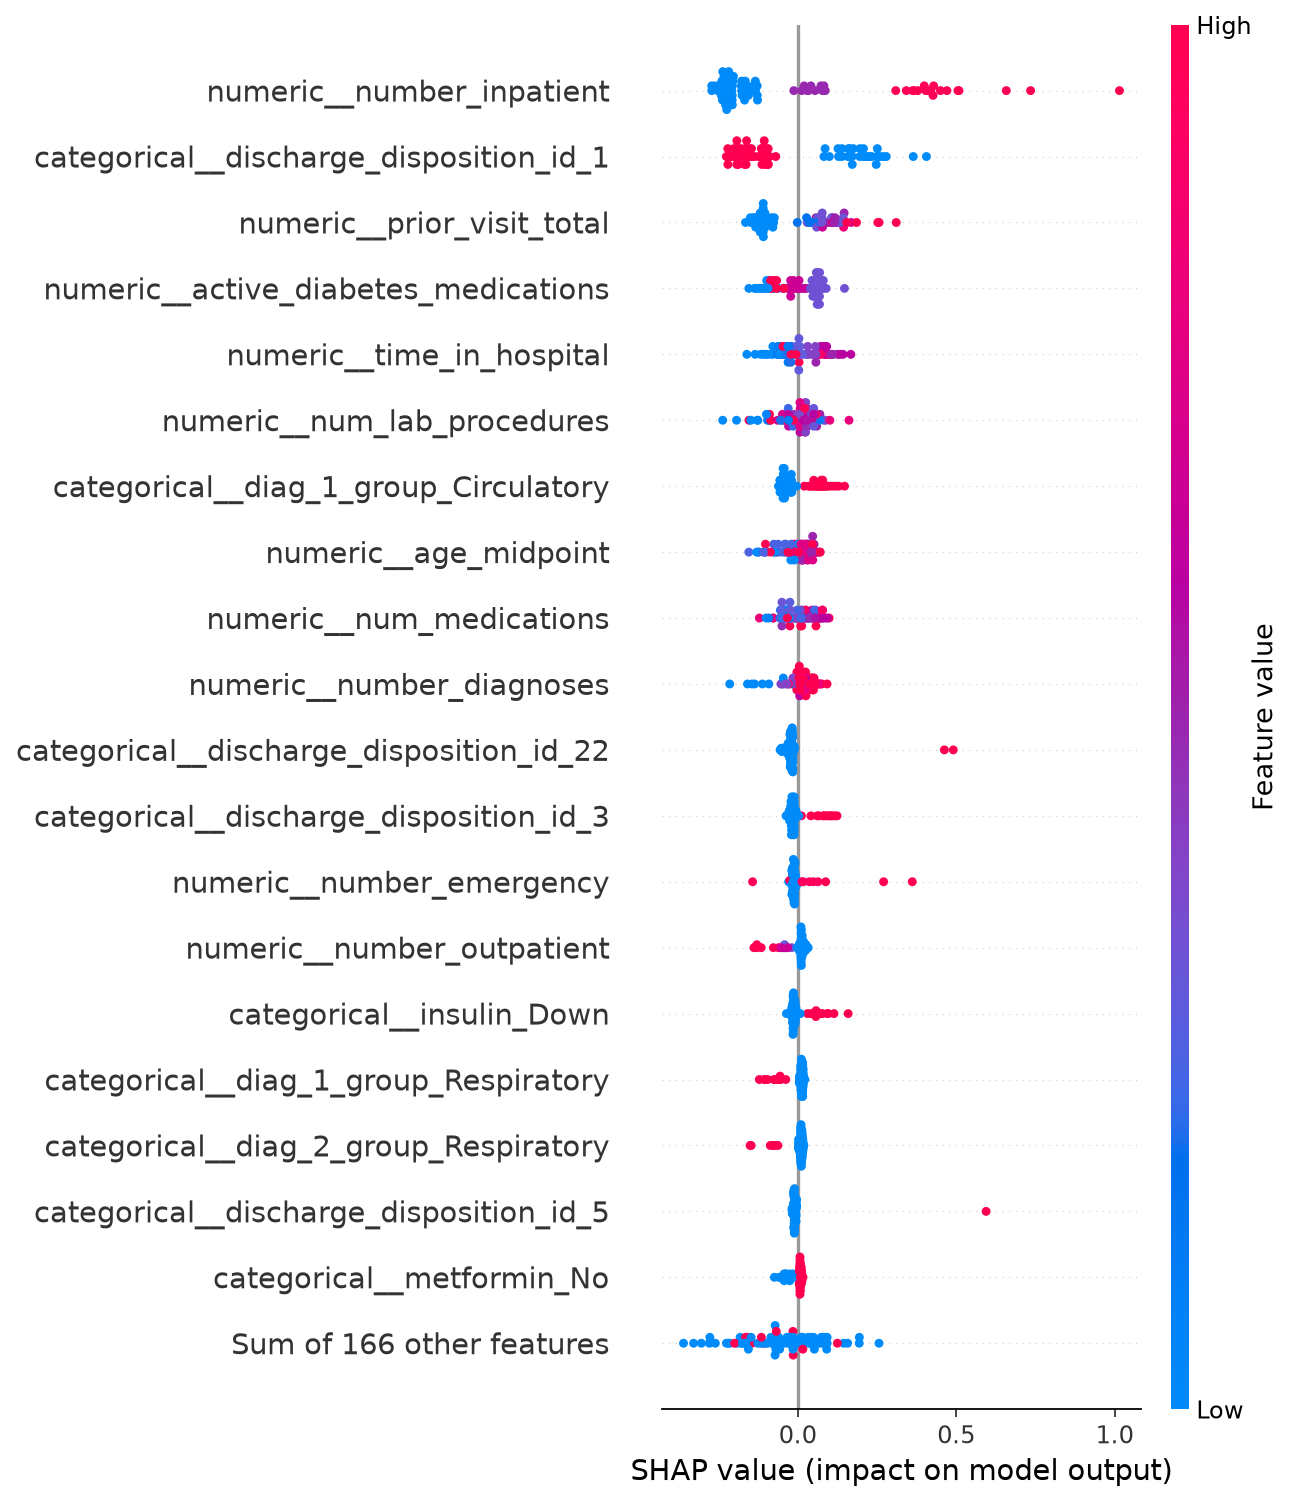

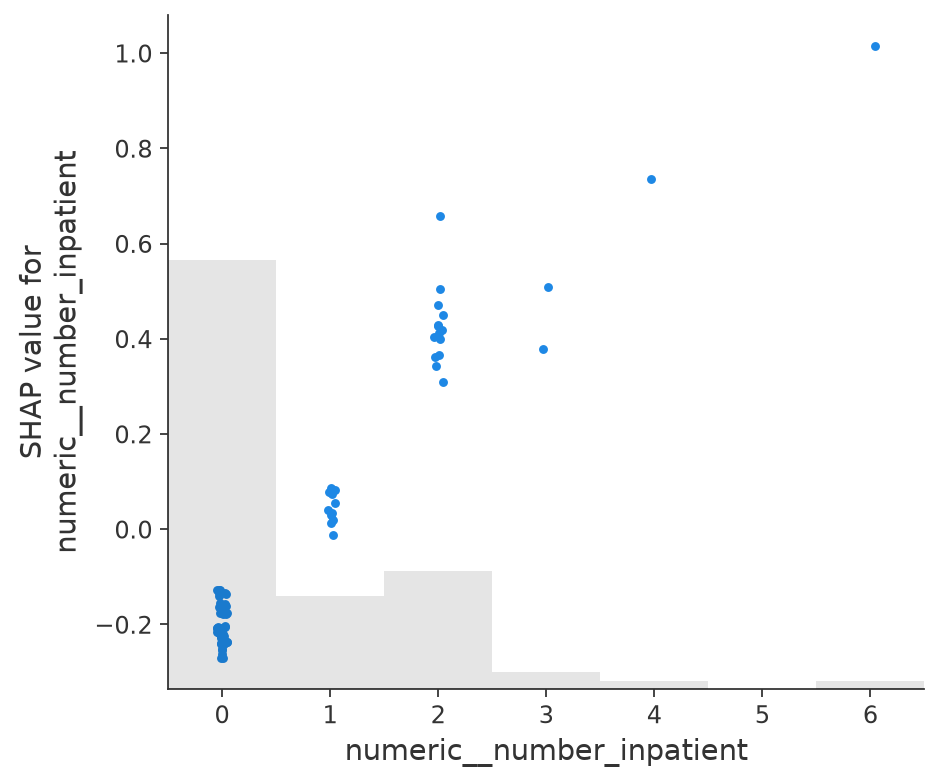

In [6]:
display(pd.Series(report("shap_summary.json")))
figure("shap_global_importance.png")
figure("shap_summary.png")
figure("shap_dependence.png")

## Clinical interpretation and future validation
This educational retrospective model is not a clinically validated prediction system. Assess precision, recall, false-positive workload and calibration together. The F2 threshold expresses an illustrative preference for recall, not an established clinical utility function. Before UK healthcare use, obtain contemporary NHS data, undertake temporal/external validation, assess coding and demographic compatibility, calibrate using development data, evaluate net benefit/capacity constraints, and conduct governance and prospective evaluation.